# Country Data Analysis Report

## Project Overview

This report presents the analysis of country-level data using Python, Pandas, and NumPy.

The analysis focuses on descriptive statistics, life expectancy, population, GDP per capita, continent-level comparisons, and yearly trends. It also demonstrates the use of NumPy for population matrix operations and compares broadcasting with loop-based calculations.

## Objectives

- Generate descriptive statistics for numerical variables.
- Analyze life expectancy, population, and GDP per capita over time.
- Compare data across continents and countries.
- Examine yearly trends.
- Apply NumPy operations to population data.
- Compare broadcasting and loop-based population index calculations.
- Export the generated analysis results.

In [6]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Add the project root to the Python path
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "output":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.readers_csv_excel import (
    read_csv_file,
    read_excel_file
)

from src.readers_json_parquet import (
    read_json_file,
    read_parquet_file
)

from src.reconciliation import reconcile_data

from src.analysis import (
    generate_descriptive_statistics,
    analyze_life_expectancy,
    analyze_population,
    analyze_gdp,
    generate_continent_summary,
    analyze_yearly_trends,
    region_population_numpy,
    build_population_matrix,
    index_by_broadcast,
    index_by_loop,
    generate_country_summary
)

from src.analysis_exports import export_analysis_results

# Configure visualizations
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

print("Libraries and project modules imported successfully.")

Libraries and project modules imported successfully.


## 1. Loading the Cleaned Dataset

The analysis uses the reconciled dataset produced by the data integration and validation process. The cleaned dataset contains the standardized country-level records from the four supported file formats.

In [7]:
# Load the reconciled dataset
cleaned_data_path = PROJECT_ROOT / "output" / "cleaned_data.csv"

data = pd.read_csv(cleaned_data_path)

# Display dataset information
print("Dataset loaded successfully.")
print(f"Total records: {len(data):,}")
print(f"Total columns: {len(data.columns)}")

display(data.head())

Dataset loaded successfully.
Total records: 1,704
Total columns: 6


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106


In [8]:
# Check the dataset structure
print("Dataset Information:")
data.info()

print("\nMissing Values:")
display(data.isnull().sum())

print("\nDuplicate Records:")
print(data.duplicated().sum())

print("\nNumber of Countries:")
print(data["country"].nunique())

print("\nYears Covered:")
print(sorted(data["year"].unique()))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 103.7 KB

Missing Values:


country      0
continent    0
year         0
lifeExp      0
pop          0
gdpPercap    0
dtype: int64


Duplicate Records:
0

Number of Countries:
142

Years Covered:
[np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]


## 2. Descriptive Statistics

This section presents the descriptive statistics of the numerical variables in the dataset. It includes the count, mean, standard deviation, minimum, maximum, and quartile values for each variable.

In [9]:
# Generate descriptive statistics using the analysis module
descriptive_statistics = generate_descriptive_statistics(data)

display(descriptive_statistics)

,year,lifeExp,pop,gdpPercap
count,1704.00000,1704.000000,1.704000e+03,1704.000000
mean,1979.50000,59.474439,2.960121e+07,7215.327081
std,17.26533,12.917107,1.061579e+08,9857.454543
min,1952.00000,23.599000,6.001100e+04,241.165876
25%,1965.75000,48.198000,2.793664e+06,1202.060309
50%,1979.50000,60.712500,7.023596e+06,3531.846988
75%,1993.25000,70.845500,1.958522e+07,9325.462346
max,2007.00000,82.603000,1.318683e+09,113523.132900


### Interpretation

The descriptive statistics show considerable variation in life expectancy, population, and GDP per capita across the 1,704 observations. Life expectancy has an average of approximately 59.47 years, while the population data show a large difference in country sizes.

The mean GDP per capita is higher than its median, suggesting that some countries have considerably higher GDP per capita values than others. Overall, these statistics provide an initial overview of the differences in living conditions and economic characteristics across countries and years.

## 3. Life Expectancy Analysis

This section examines the average life expectancy across all countries for each year. A line chart is used to visualize how average life expectancy changed throughout the observation period.

,year,average_life_expectancy
0,1952,49.057620
1,1957,51.507401
2,1962,53.609249
3,1967,55.678290
4,1972,57.647386
5,1977,59.570157
6,1982,61.533197
7,1987,63.212613
8,1992,64.160338
9,1997,65.014676


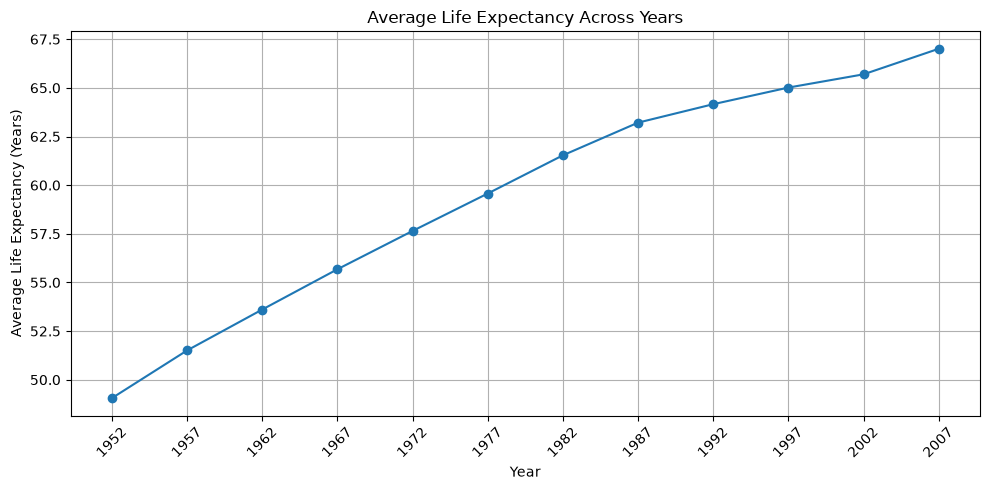

In [10]:
# Analyze average life expectancy by year
life_expectancy = analyze_life_expectancy(data)

display(life_expectancy)

# Visualize life expectancy trends
plt.figure()

plt.plot(
    life_expectancy["year"],
    life_expectancy["average_life_expectancy"],
    marker="o"
)

plt.title("Average Life Expectancy Across Years")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy (Years)")
plt.xticks(life_expectancy["year"], rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

The results show a consistent increase in average life expectancy from approximately 49.06 years in 1952 to 67.01 years in 2007. This represents an overall improvement of nearly 18 years throughout the observation period.

The line graph illustrates a steady upward trend, suggesting improvements in overall life expectancy across the countries included in the dataset. However, the values represent global averages across the available country records, so individual countries may have experienced different patterns of change.

## 4. Population Analysis

This section examines the total population across all countries for each year. A line chart is used to visualize population changes throughout the observation period.

,year,total_population
0,1952,2406957150
1,1957,2664404580
2,1962,2899782974
3,1967,3217478384
4,1972,3576977158
5,1977,3930045807
6,1982,4289436840
7,1987,4691477418
8,1992,5110710260
9,1997,5515204472


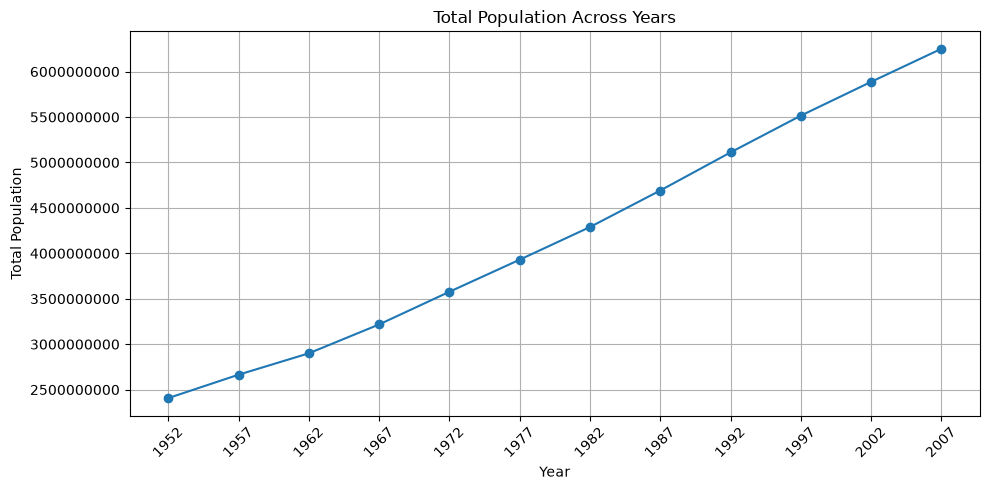

In [11]:
# Analyze total population by year
population_analysis = analyze_population(data)

display(population_analysis)

# Visualize population trends
plt.figure()

plt.plot(
    population_analysis["year"],
    population_analysis["total_population"],
    marker="o"
)

plt.title("Total Population Across Years")
plt.xlabel("Year")
plt.ylabel("Total Population")
plt.xticks(population_analysis["year"], rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### Interpretation

The results show a continuous increase in the combined population of the 142 countries included in the dataset. In 1952, their total population was approximately 2.41 billion, which increased to 6.25 billion by 2007.

The line graph illustrates a consistent upward trend throughout the observation period. This indicates substantial population growth across the countries represented in the dataset. The increase also highlights the importance of considering population changes when examining economic and social development.

## 5. GDP per Capita Analysis

This section examines the average GDP per capita across countries for each year. The analysis provides an overview of how the average economic output per person changed throughout the observation period.

,year,average_gdp_per_capita
0,1952,3725.276046
1,1957,4299.408345
2,1962,4725.812342
3,1967,5483.653047
4,1972,6770.082815
5,1977,7313.166421
6,1982,7518.901673
7,1987,7900.920218
8,1992,8158.608521
9,1997,9090.175363


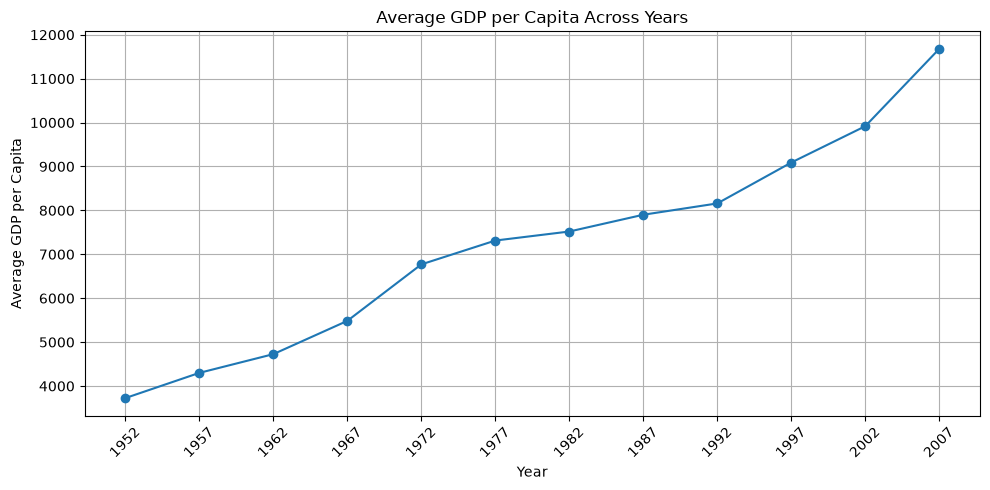

In [12]:
# Analyze average GDP per capita by year
gdp_analysis = analyze_gdp(data)

display(gdp_analysis)

# Visualize GDP per capita trends
plt.figure()

plt.plot(
    gdp_analysis["year"],
    gdp_analysis["average_gdp_per_capita"],
    marker="o"
)

plt.title("Average GDP per Capita Across Years")
plt.xlabel("Year")
plt.ylabel("Average GDP per Capita")
plt.xticks(gdp_analysis["year"], rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

The results show an overall increase in average GDP per capita from approximately 3,725.28 in 1952 to 11,680.07 in 2007. This indicates an improvement in the average economic output per person across the countries included in the dataset.

The line graph shows that growth was relatively gradual during some periods, while more noticeable increases occurred between 1967 and 1977 and from 1992 to 2007. These results suggest that the economic conditions of the countries generally improved over the observation period, although the average does not reflect the differences in economic performance among individual countries.

## 6. Continent-Level Analysis

This section compares the average life expectancy, population, and GDP per capita across continents. The summary helps identify differences in demographic and economic characteristics among the regions represented in the dataset.

In [13]:
# Generate continent-level summary
continent_summary = generate_continent_summary(data)

display(continent_summary)

,continent,lifeExp,pop,gdpPercap
0,Africa,48.865330,9.916003e+06,2193.754578
1,Americas,64.658737,2.450479e+07,7136.110356
2,Asia,60.064903,7.703872e+07,7902.150428
3,Europe,71.903686,1.716976e+07,14469.475533
4,Oceania,74.326208,8.874672e+06,18621.609223


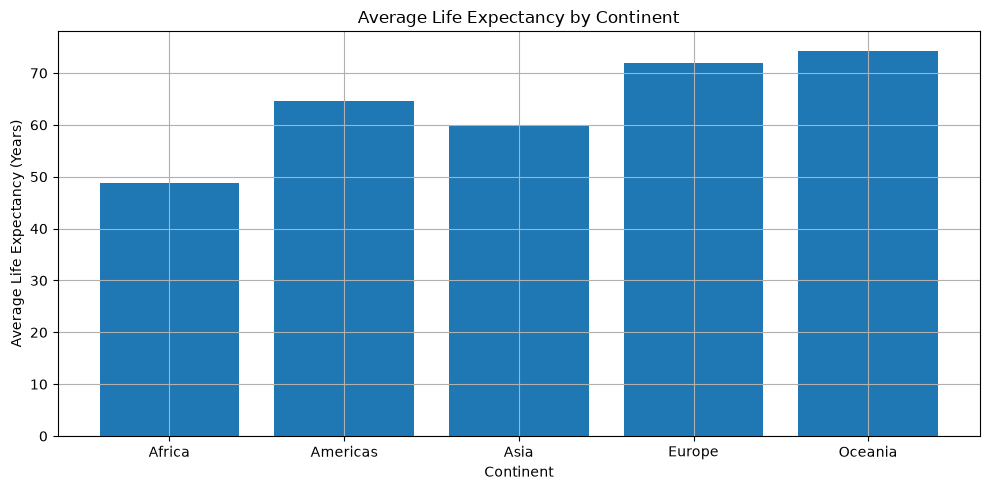

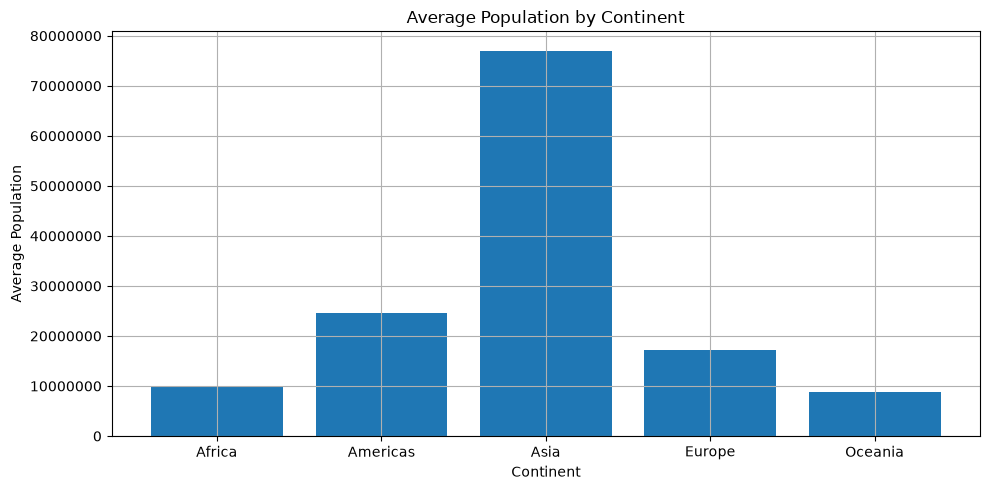

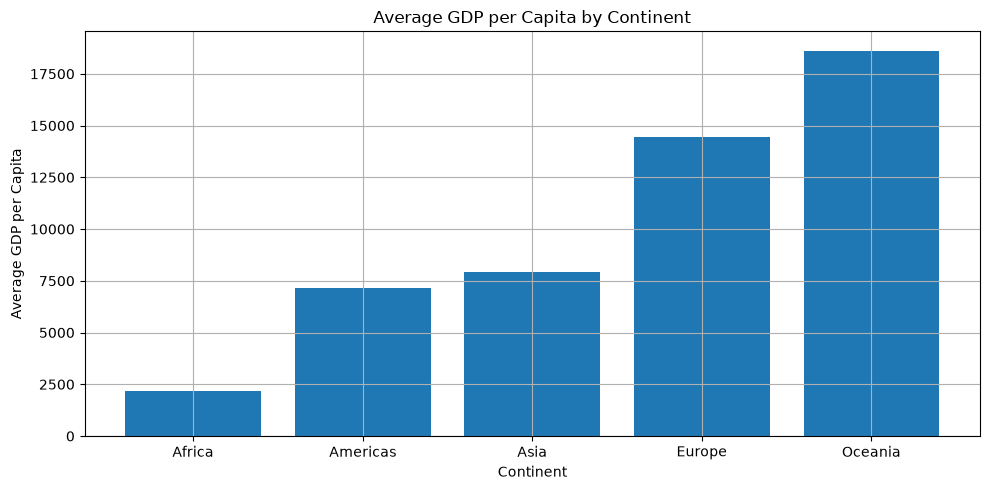

In [14]:
# Compare average life expectancy across continents
plt.figure()

plt.bar(
    continent_summary["continent"],
    continent_summary["lifeExp"]
)

plt.title("Average Life Expectancy by Continent")
plt.xlabel("Continent")
plt.ylabel("Average Life Expectancy (Years)")
plt.tight_layout()
plt.show()


# Compare average population across continents
plt.figure()

plt.bar(
    continent_summary["continent"],
    continent_summary["pop"]
)

plt.title("Average Population by Continent")
plt.xlabel("Continent")
plt.ylabel("Average Population")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


# Compare average GDP per capita across continents
plt.figure()

plt.bar(
    continent_summary["continent"],
    continent_summary["gdpPercap"]
)

plt.title("Average GDP per Capita by Continent")
plt.xlabel("Continent")
plt.ylabel("Average GDP per Capita")
plt.tight_layout()
plt.show()

### Interpretation

The continent-level summary reveals differences in life expectancy, population, and GDP per capita across the five continents.

For average life expectancy, Oceania records the highest value at approximately 74.33 years, followed by Europe at 71.90 years. Africa has the lowest average at 48.87 years.

In terms of average population, Asia has the highest value at approximately 77 million, which is considerably higher than the other continents. This reflects the presence of highly populated countries within the region.

For GDP per capita, Oceania has the highest average at approximately 18,621.61, followed by Europe at 14,469.48. Meanwhile, Africa has the lowest average at approximately 2,193.75.

Overall, the results highlight the differences in demographic and economic characteristics across continents. However, these figures represent averages across all available country-year observations from 1952 to 2007 and should not be interpreted as current statistics or as conditions experienced by every country within each continent.

## 7. Country-Level Analysis

This section generates summary statistics for each country. It provides an overview of the average life expectancy, population, and GDP per capita across the available observation years.

In [15]:
# Generate country-level summary
country_summary = generate_country_summary(data)

display(country_summary.head(10))

print("Total countries:", len(country_summary))

,country,continent,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,37.478833,1.582372e+07,802.674598
1,Albania,Europe,68.432917,2.580249e+06,3255.366633
2,Algeria,Africa,59.030167,1.987541e+07,4426.025973
3,Angola,Africa,37.883500,7.309390e+06,3607.100529
4,Argentina,Americas,69.060417,2.860224e+07,8955.553783
5,Australia,Oceania,74.662917,1.464931e+07,19980.595634
6,Austria,Europe,73.103250,7.583298e+06,20411.916279
7,Bahrain,Asia,65.605667,3.739132e+05,18077.663945
8,Bangladesh,Asia,49.834083,9.075540e+07,817.558818
9,Belgium,Europe,73.641750,9.725119e+06,19900.758072


Total countries: 142


In [16]:
# Countries with the highest and lowest average life expectancy
highest_life_expectancy = country_summary.nlargest(5, "lifeExp")
lowest_life_expectancy = country_summary.nsmallest(5, "lifeExp")

print("Top 5 Countries by Average Life Expectancy")
display(highest_life_expectancy[["country", "continent", "lifeExp"]])

print("Bottom 5 Countries by Average Life Expectancy")
display(lowest_life_expectancy[["country", "continent", "lifeExp"]])


# Countries with the highest and lowest average GDP per capita
highest_gdp = country_summary.nlargest(5, "gdpPercap")
lowest_gdp = country_summary.nsmallest(5, "gdpPercap")

print("Top 5 Countries by Average GDP per Capita")
display(highest_gdp[["country", "continent", "gdpPercap"]])

print("Bottom 5 Countries by Average GDP per Capita")
display(lowest_gdp[["country", "continent", "gdpPercap"]])

Top 5 Countries by Average Life Expectancy


,country,continent,lifeExp
57,Iceland,Europe,76.511417
122,Sweden,Europe,76.177000
95,Norway,Europe,75.843000
90,Netherlands,Europe,75.648500
123,Switzerland,Europe,75.565083


Bottom 5 Countries by Average Life Expectancy


,country,continent,lifeExp
112,Sierra Leone,Africa,36.769167
0,Afghanistan,Asia,37.478833
3,Angola,Africa,37.883500
52,Guinea-Bissau,Africa,39.210250
86,Mozambique,Africa,40.379500


Top 5 Countries by Average GDP per Capita


,country,continent,gdpPercap
71,Kuwait,Asia,65332.910472
123,Switzerland,Europe,27074.334405
95,Norway,Europe,26747.306554
134,United States,Americas,26261.151347
20,Canada,Americas,22410.746340


Bottom 5 Countries by Average GDP per Capita


,country,continent,gdpPercap
87,Myanmar,Asia,439.333333
17,Burundi,Africa,471.662990
42,Ethiopia,Africa,509.115155
41,Eritrea,Africa,541.002507
86,Mozambique,Africa,542.278332


### Interpretation

The country-level analysis highlights the differences in average life expectancy, population, and GDP per capita among the 142 countries included in the dataset.

Iceland has the highest average life expectancy at approximately 76.51 years, followed by Sweden, Norway, the Netherlands, and Switzerland. On the other hand, Sierra Leone records the lowest average at approximately 36.77 years. The five countries with the highest average life expectancy are all located in Europe, while most of the countries with the lowest averages are in Africa.

For GDP per capita, Kuwait records the highest average at approximately 65,332.91, followed by Switzerland, Norway, the United States, and Canada. Meanwhile, Myanmar has the lowest average at approximately 439.33, followed by Burundi, Ethiopia, Eritrea, and Mozambique.

Overall, the results demonstrate considerable differences in economic and demographic conditions among individual countries. They also show that continent-level averages may not fully represent the conditions of every country within a region. These rankings are based on averages from 1952 to 2007 and should not be interpreted as current country rankings.

## 8. Yearly Trends Analysis

This section examines the yearly changes in average life expectancy, total population, and average GDP per capita. It combines these indicators into one summary to provide a broader view of demographic and economic trends over time.

In [17]:
# Generate yearly trends
yearly_trends = analyze_yearly_trends(data)

display(yearly_trends)

,year,lifeExp,pop,gdpPercap
0,1952,49.057620,2406957150,3725.276046
1,1957,51.507401,2664404580,4299.408345
2,1962,53.609249,2899782974,4725.812342
3,1967,55.678290,3217478384,5483.653047
4,1972,57.647386,3576977158,6770.082815
5,1977,59.570157,3930045807,7313.166421
6,1982,61.533197,4289436840,7518.901673
7,1987,63.212613,4691477418,7900.920218
8,1992,64.160338,5110710260,8158.608521
9,1997,65.014676,5515204472,9090.175363


### Interpretation

The yearly trends analysis shows a consistent increase in life expectancy, total population, and average GDP per capita from 1952 to 2007.

Average life expectancy increased from approximately 49.06 years in 1952 to 67.01 years in 2007. Meanwhile, the combined population grew from approximately 2.41 billion to 6.25 billion. Average GDP per capita also increased from 3,725.28 to 11,680.07 during the same period.

These trends indicate overall improvements in life expectancy and economic output alongside substantial population growth across the countries represented in the dataset. Examining these indicators together provides a broader understanding of the demographic and economic changes that occurred throughout the observation period.

## 9. NumPy-Based Population Analysis

This section demonstrates the use of NumPy for processing population data. It includes filtering country records by continent and year, constructing a population matrix, and calculating population indexes using broadcasting and nested loops.

In [18]:
# Analyze the population of Asian countries in 2007
region = "Asia"
selected_year = 2007

country_count, total_population = region_population_numpy(
    data,
    region,
    selected_year
)

print("Region:", region)
print("Year:", selected_year)
print("Number of Countries:", country_count)
print("Total Population:", f"{total_population:,}")

Region: Asia
Year: 2007
Number of Countries: 33
Total Population: 3,811,953,827


### Interpretation

The NumPy-based population analysis successfully identified 33 countries in Asia for the year 2007, with a combined population of 3,811,953,827.

The results match the expected values specified in the project manifest, confirming that the function correctly filters the dataset using the selected continent and year. It also demonstrates how NumPy arrays and Boolean indexing can efficiently process population records.

### Population Matrix Construction

A population matrix is constructed using NumPy, with each row representing a country and each column representing a year. This structure allows population values to be organized for efficient numerical operations and comparisons across different years.

In [19]:
# Get unique countries and years
countries = sorted(data["country"].unique())
years = sorted(data["year"].unique())

# Build the population matrix
population_matrix = build_population_matrix(
    data,
    countries,
    years
)

print("Population Matrix Shape:", population_matrix.shape)

# Display a preview of the matrix
population_matrix_preview = pd.DataFrame(
    population_matrix[:5, :],
    index=countries[:5],
    columns=years
)

display(population_matrix_preview)

Population Matrix Shape: (142, 12)


,1952,1957,1962,1967,1972,1977,1982,1987,1992,1997,2002,2007
Afghanistan,8425333,9240934,10267083,11537966,13079460,14880372,12881816,13867957,16317921,22227415,25268405,31889923
Albania,1282697,1476505,1728137,1984060,2263554,2509048,2780097,3075321,3326498,3428038,3508512,3600523
Algeria,9279525,10270856,11000948,12760499,14760787,17152804,20033753,23254956,26298373,29072015,31287142,33333216
Angola,4232095,4561361,4826015,5247469,5894858,6162675,7016384,7874230,8735988,9875024,10866106,12420476
Argentina,17876956,19610538,21283783,22934225,24779799,26983828,29341374,31620918,33958947,36203463,38331121,40301927


### Interpretation

The population matrix successfully organizes the population data of 142 countries across 12 observation years, resulting in a matrix with dimensions of 142 × 12.

Each row represents an individual country, while each column corresponds to a specific year from 1952 to 2007. Each cell contains the population value for the corresponding country and year.

This matrix structure makes it easier to perform numerical operations and compare population changes across countries and years. The successful construction also confirms that every country has exactly one population record for each observation year.

### Population Index Using Broadcasting

This section calculates the population index of each country using 1952 as the baseline year. NumPy broadcasting is used to divide each year's population by the corresponding country's baseline population and multiply the result by 100.

In [20]:
# Calculate population indexes using broadcasting
broadcast_index, baseline_shape, index_shape = index_by_broadcast(
    population_matrix,
    0
)

print("Baseline Shape:", baseline_shape)
print("Index Matrix Shape:", index_shape)

# Display a preview
broadcast_preview = pd.DataFrame(
    broadcast_index[:5, :],
    index=countries[:5],
    columns=years
)

display(broadcast_preview.round(2))

Baseline Shape: (142, 1)
Index Matrix Shape: (142, 12)


,1952,1957,1962,1967,1972,1977,1982,1987,1992,1997,2002,2007
Afghanistan,100.0,109.68,121.86,136.94,155.24,176.61,152.89,164.60,193.68,263.82,299.91,378.50
Albania,100.0,115.11,134.73,154.68,176.47,195.61,216.74,239.75,259.34,267.25,273.53,280.70
Algeria,100.0,110.68,118.55,137.51,159.07,184.85,215.89,250.61,283.40,313.29,337.16,359.21
Angola,100.0,107.78,114.03,123.99,139.29,145.62,165.79,186.06,206.42,233.34,256.75,293.48
Argentina,100.0,109.70,119.06,128.29,138.61,150.94,164.13,176.88,189.96,202.51,214.42,225.44


### Interpretation

The population index calculation using NumPy broadcasting successfully generated a matrix with dimensions of 142 × 12. The baseline array has dimensions of 142 × 1, allowing each country's population values to be divided by its corresponding population in 1952.

All countries have an index value of 100 in 1952 because it serves as the reference year. For example, Afghanistan has an index of 378.50 in 2007, indicating that its population grew to approximately 3.78 times its 1952 population.

The results demonstrate how NumPy broadcasting can perform calculations across entire arrays without requiring explicit loops for individual elements.

### Population Index Using Nested Loops

This section calculates the same population indexes using nested loops. Each country's population values are processed individually using its 1952 population as the baseline. The results will be compared with the broadcasting implementation.

In [21]:
# Calculate population indexes using nested loops
loop_index = index_by_loop(population_matrix, 0)

print("Loop Index Matrix Shape:", loop_index.shape)

# Display a preview
loop_preview = pd.DataFrame(
    loop_index[:5, :],
    index=countries[:5],
    columns=years
)

display(loop_preview.round(2))

Loop Index Matrix Shape: (142, 12)


,1952,1957,1962,1967,1972,1977,1982,1987,1992,1997,2002,2007
Afghanistan,100.0,109.68,121.86,136.94,155.24,176.61,152.89,164.60,193.68,263.82,299.91,378.50
Albania,100.0,115.11,134.73,154.68,176.47,195.61,216.74,239.75,259.34,267.25,273.53,280.70
Algeria,100.0,110.68,118.55,137.51,159.07,184.85,215.89,250.61,283.40,313.29,337.16,359.21
Angola,100.0,107.78,114.03,123.99,139.29,145.62,165.79,186.06,206.42,233.34,256.75,293.48
Argentina,100.0,109.70,119.06,128.29,138.61,150.94,164.13,176.88,189.96,202.51,214.42,225.44


In [22]:
# Compare broadcasting and loop results
are_equal = np.allclose(broadcast_index, loop_index)

print("Broadcasting and Loop Results Match:", are_equal)

Broadcasting and Loop Results Match: True


### Interpretation

The nested-loop implementation successfully generated a population index matrix with dimensions of 142 × 12, matching the dimensions of the broadcasting implementation.

The displayed values are also consistent across both methods. The comparison using NumPy's `allclose()` function returned `True`, confirming that both implementations produce numerically equivalent results.

Although both approaches generate the same output, broadcasting performs the calculations across arrays directly, while the nested-loop approach processes each country and year individually. This demonstrates how NumPy broadcasting can simplify array operations and avoid explicitly iterating through every element.

## Exporting Analysis Results

This section exports the generated analysis tables into CSV files. These files provide reusable outputs for further analysis, reporting, and documentation.

In [23]:
# Create output directory if it does not exist
output_directory = PROJECT_ROOT / "output"
output_directory.mkdir(exist_ok=True)

# Export analysis results
export_analysis_results(
    descriptive_statistics,
    output_directory / "descriptive_statistics.csv"
)

export_analysis_results(
    life_expectancy,
    output_directory / "life_expectancy_analysis.csv"
)

export_analysis_results(
    population_analysis,
    output_directory / "population_analysis.csv"
)

export_analysis_results(
    gdp_analysis,
    output_directory / "gdp_analysis.csv"
)

export_analysis_results(
    continent_summary,
    output_directory / "continent_summary.csv"
)

export_analysis_results(
    country_summary,
    output_directory / "country_summary.csv"
)

export_analysis_results(
    yearly_trends,
    output_directory / "yearly_trends.csv"
)

print("Analysis results exported successfully.")

Analysis results exported successfully.


## Conclusion

The analysis successfully examined country-level data from 1952 to 2007 using Pandas and NumPy. The results showed overall increases in average life expectancy, combined population, and average GDP per capita throughout the observed period.

The continent-level and country-level comparisons also revealed differences in life expectancy, population, and GDP per capita across geographical areas. These findings demonstrate that development patterns varied among countries and continents.

The NumPy analysis further demonstrated how population data can be organized into matrices and processed using broadcasting and nested loops. Both implementations produced equivalent population index results, while broadcasting provided a more direct approach to array calculations.

Finally, the analysis results were successfully exported into CSV files for future use. Overall, the project demonstrated how data analysis and numerical computing techniques can be applied to organize, examine, compare, and summarize large datasets.